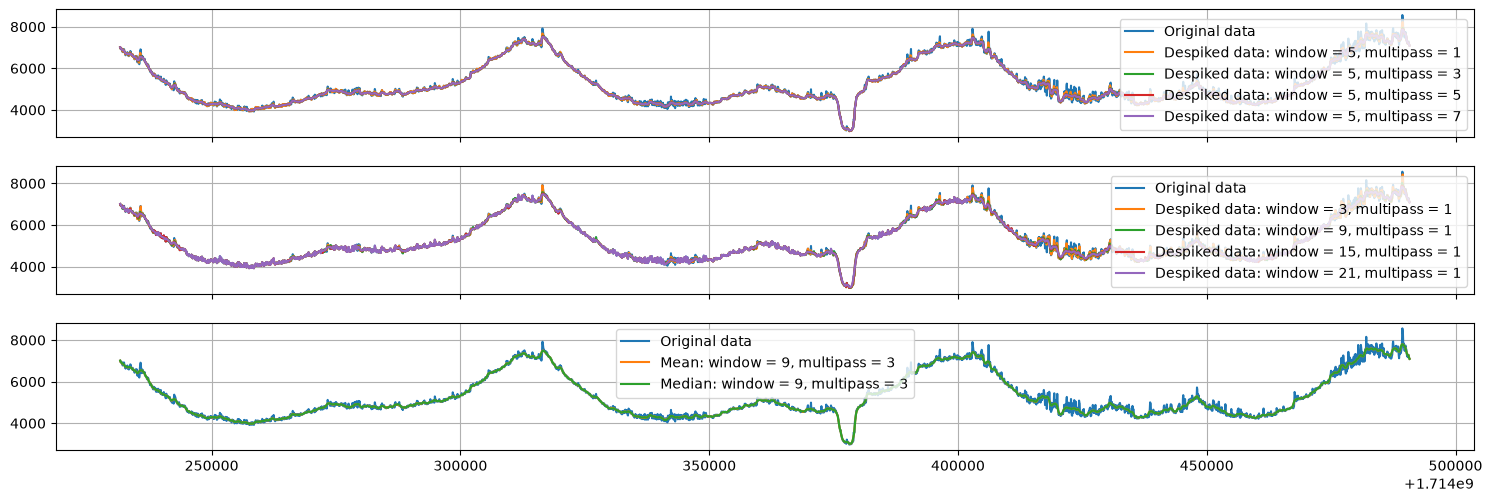

In [7]:
import matplotlib.pyplot as plt
import yaml

from despiker import despiked


with open("./test_data.json") as df:
    data = yaml.safe_load(df)[:]

arguments, values = [t for t, _ in data], [v for _, v in data]

fig, (plot_multipass, plot_window, plot_method) = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(15, 5))
fig.tight_layout()

plot_multipass.plot(arguments, values, label="Original data")
w = 5
for p in [1, 3, 5, 7]:
    nx, ny = despiked(values, arguments, window=w, multipass=p)
    plot_multipass.plot(nx, ny, label=f"Despiked data: window = {w}, multipass = {p}")
plot_multipass.grid()
plot_multipass.legend()

plot_window.plot(arguments, values, label="Original data")
p = 1
for w in [3, 9, 15, 21]:
    nx, ny = despiked(values, arguments, window=w, multipass=p)
    plot_window.plot(nx, ny, label=f"Despiked data: window = {w}, multipass = {p}")
plot_window.grid()
plot_window.legend()

plot_method.plot(arguments, values, label="Original data")
w, p = 9, 3
nx, ny = despiked(values, arguments, window=9, multipass=3, method="mean")
plot_method.plot(nx, ny, label=f"Mean: window = {w}, multipass = {p}")
nx, ny = despiked(values, arguments, window=9, multipass=3, method="median")
plot_method.plot(nx, ny, label=f"Median: window = {w}, multipass = {p}")
plot_method.grid()
plot_method.legend()

plt.show()